# Exp 6 – LightGBM Classifier with Optuna Optimization

1. One-Hot Encoding (OHE) is applied to categorical features.
2. Class imbalance is handled using scale_pos_weight, calculated from the model training data.
3. The original training data is split into model training (80%) and validation (20%), keeping the test set untouched.
4. Optuna with 40 trials and 5-Fold Stratified CV is used to optimize LightGBM hyperparameters based on PR-AUC.
5. The best model is trained using the selected hyperparameters.
6. The best model generates churn probabilities on the validation set.
7. Validation probabilities are used to select the best classification threshold based on F1 Score.
8. The selected threshold is applied to training, validation, and test probabilities to generate:
   0 = Retained | 1 = Churned.
9. Model performance is evaluated using classification metrics, confusion matrix, and cross-validation.
10. Feature importance is analysed to identify the most influential features.

### 1. IMPORT LIBRARIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import optuna
import warnings

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_score
)
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
sns.set_theme(style='darkgrid')

In [2]:
df = pd.read_csv("../../task3/feature_eng_df.csv")

### 2. SEPARATE FEATURES AND TARGET

In [3]:
date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols)
y = df['churn']

print("Total Missing Values:", X.isna().sum().sum())
print("\nTarget Distribution:")
print(y.value_counts())
print("\nTarget Percentage:")
print(y.value_counts(normalize=True) * 100)

Total Missing Values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.284814
1     9.715186
Name: proportion, dtype: float64


### 3. ORIGINAL TRAIN-TEST SPLIT

In [4]:
X_train_original, X_test, y_train_original, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nOriginal Training Data:", X_train_original.shape)
print("Original Test Data:", X_test.shape)


Original Training Data: (11684, 104)
Original Test Data: (2922, 104)


### 4. MODEL TRAINING AND THRESHOLD VALIDATION SPLIT

In [5]:
X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train_original,
    y_train_original,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train_original
)

print("\nModel Training Data:", X_model_train.shape)
print("Threshold Validation Data:", X_val.shape)
print("Final Test Data:", X_test.shape)


Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)
Final Test Data: (2922, 104)


### 5. IDENTIFY FEATURE TYPES

In [6]:
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:", categorical_cols)
print("Numerical Columns:", len(numerical_cols))


Categorical Columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical Columns: 101


### 6. PREPROCESSING

In [7]:
categorical_pipeline = OneHotEncoder(
    handle_unknown='ignore'
)

preprocessor = make_column_transformer(
    (categorical_pipeline, categorical_cols),
    remainder='passthrough',
    verbose_feature_names_out=False,
    n_jobs=-1
)

### 7. CLASS IMBALANCE

In [8]:
negative_count = (y_model_train == 0).sum()
positive_count = (y_model_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("\n==== CLASS IMBALANCE ====")
print("Negative Class:", negative_count)
print("Positive Class:", positive_count)
print("Scale Pos Weight:", scale_pos_weight)


==== CLASS IMBALANCE ====
Negative Class: 8439
Positive Class: 908
Scale Pos Weight: 9.294052863436123


### 8. OPTUNA OBJECTIVE FUNCTION

In [9]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

def objective(trial):
    max_depth = trial.suggest_int('max_depth', 3, 10)

    params = {
        'n_estimators': trial.suggest_int(
            'n_estimators', 200, 1000, step=100
        ),
        'learning_rate': trial.suggest_float(
            'learning_rate', 0.01, 0.10, log=True
        ),
        'max_depth': max_depth,
        'num_leaves': trial.suggest_int(
            'num_leaves', 7, min(64, 2 ** max_depth)
        ),
        'min_child_samples': trial.suggest_int(
            'min_child_samples', 10, 100, step=5
        ),
        'subsample': trial.suggest_float(
            'subsample', 0.6, 1.0
        ),
        'subsample_freq': 1,
        'colsample_bytree': trial.suggest_float(
            'colsample_bytree', 0.5, 1.0
        ),
        'reg_alpha': trial.suggest_float(
            'reg_alpha', 0.01, 20.0, log=True
        ),
        'reg_lambda': trial.suggest_float(
            'reg_lambda', 0.01, 50.0, log=True
        ),
        'min_split_gain': trial.suggest_float(
            'min_split_gain', 0.0, 5.0
        ),
        'scale_pos_weight': trial.suggest_float(
            'scale_pos_weight', 1.0, scale_pos_weight
        ),
        'objective': 'binary',
        'random_state': RANDOM_STATE,
        'n_jobs': -1,
        'verbosity': -1
    }

    model = lgb.LGBMClassifier(**params)

    pipeline = Pipeline(steps=[
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    scores = cross_val_score(
        pipeline,
        X_model_train,
        y_model_train,
        scoring='average_precision',
        cv=cv,
        n_jobs=1
    )

    return scores.mean()

### 9. RUN OPTUNA

In [10]:
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study.optimize(
    objective,
    n_trials=40,
    show_progress_bar=True
)

  0%|          | 0/40 [00:00<?, ?it/s]

### 10. BEST HYPERPARAMETERS

In [11]:
print("\n==== BEST HYPERPARAMETERS ====")
print(study.best_params)

print("\nBest CV PR-AUC:")
print(study.best_value)


==== BEST HYPERPARAMETERS ====
{'max_depth': 10, 'n_estimators': 300, 'learning_rate': 0.035210016213229674, 'num_leaves': 49, 'min_child_samples': 25, 'subsample': 0.9276121219028756, 'colsample_bytree': 0.9807193888618126, 'reg_alpha': 3.0944983066931293, 'reg_lambda': 1.1302881181802555, 'min_split_gain': 0.027296515025550017, 'scale_pos_weight': 1.966097826958542}

Best CV PR-AUC:
0.28627126464270003


### 11. TOP 10 HYPERPARAMETER COMBINATIONS

In [12]:
trials_df = study.trials_dataframe()

top_trials = trials_df.sort_values(
    by='value',
    ascending=False
).head(10)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
print(top_trials.to_string(index=False))


==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 number    value             datetime_start          datetime_complete               duration  params_colsample_bytree  params_learning_rate  params_max_depth  params_min_child_samples  params_min_split_gain  params_n_estimators  params_num_leaves  params_reg_alpha  params_reg_lambda  params_scale_pos_weight  params_subsample    state
     35 0.286271 2026-11-25 16:04:03.965020 2026-11-25 16:04:14.295585 0 days 00:00:10.330565                 0.980719              0.035210                10                        25               0.027297                  300                 49          3.094498           1.130288                 1.966098          0.927612 COMPLETE
     22 0.281999 2026-11-25 16:02:39.603224 2026-11-25 16:02:45.815197 0 days 00:00:06.211973                 0.943585              0.050913                 9                        10               0.630777                  200                 53          1.892296           0.29

### 12. TRAIN FINAL LIGHTGBM MODEL

In [13]:
best_params = study.best_params.copy()

best_params.update({
    'objective': 'binary',
    'random_state': RANDOM_STATE,
    'n_jobs': -1,
    'verbosity': -1,
    'subsample_freq': 1
})

best_lgbm_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', lgb.LGBMClassifier(**best_params))
])

best_lgbm_pipeline.fit(
    X_model_train,
    y_model_train
)

print("\nFinal LightGBM Model Trained Successfully.")


Final LightGBM Model Trained Successfully.


### 13. VALIDATION PROBABILITIES

In [14]:
y_prob_val = best_lgbm_pipeline.predict_proba(X_val)[:, 1]

### 14. PRECISION-RECALL CURVE

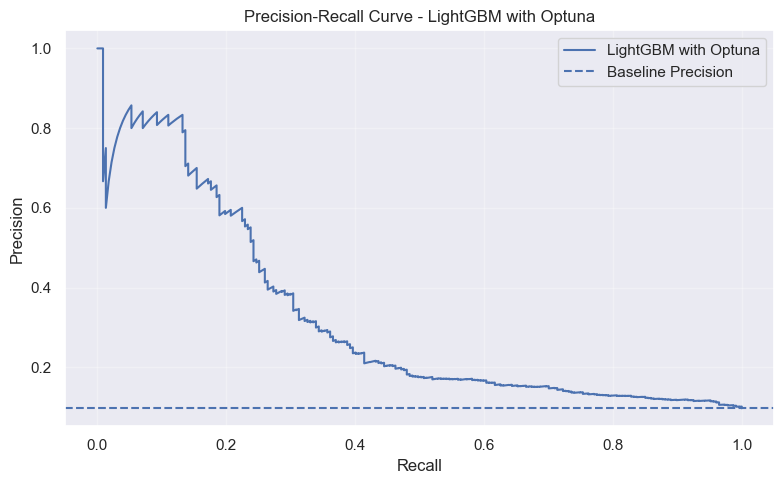

In [15]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall,
    precision,
    label='LightGBM with Optuna'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - LightGBM with Optuna')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 15. FINE-GRAINED THRESHOLD ANALYSIS

In [16]:
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    precision_value = precision_score(
        y_val, y_pred,
        zero_division=0
    )
    recall_value = recall_score(
        y_val, y_pred,
        zero_division=0
    )
    f1_value = f1_score(
        y_val, y_pred,
        zero_division=0
    )

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_value,
        'Recall': recall_value,
        'F1 Score': f1_value
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1233  0.8546    0.2154
      0.06     0.1294  0.7930    0.2225
      0.07     0.1371  0.7489    0.2318
      0.08     0.1471  0.7137    0.2440
      0.09     0.1535  0.6652    0.2494
      0.10     0.1593  0.6167    0.2532
      0.11     0.1686  0.5859    0.2618
      0.12     0.1709  0.5374    0.2593
      0.13     0.1766  0.4978    0.2607
      0.14     0.1896  0.4802    0.2718
      0.15     0.2008  0.4626    0.2800
      0.16     0.2104  0.4449    0.2857
      0.17     0.2133  0.4229    0.2836
      0.18     0.2254  0.4141    0.2919
      0.19     0.2370  0.4009    0.2979
      0.20     0.2550  0.3921    0.3090
      0.21     0.2632  0.3744    0.3091
      0.22     0.2730  0.3656    0.3126
      0.23     0.2903  0.3568    0.3202
      0.24     0.3020  0.3392    0.3195
      0.25     0.3128  0.3348    0.3234
      0.26     0.3188  0.3216    0.3202
      0.27     0.3257  0.3128    0.31

### 16. THRESHOLD PERFORMANCE VISUALIZATION

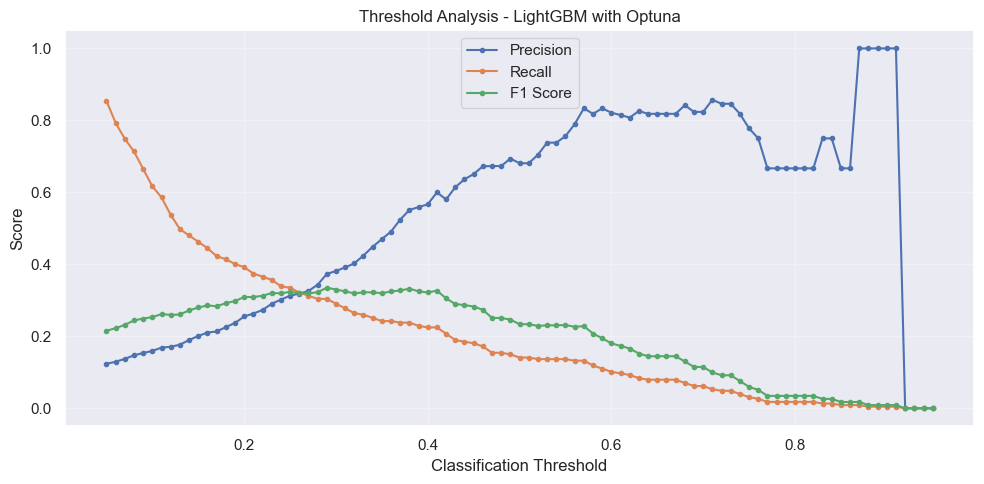

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    markersize=3,
    label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    markersize=3,
    label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    markersize=3,
    label='F1 Score'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - LightGBM with Optuna')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 17. SELECT BEST THRESHOLD

In [18]:
best_threshold_idx = fine_threshold_df['F1 Score'].idxmax()

best_threshold = fine_threshold_df.loc[
    best_threshold_idx, 'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", best_threshold)
print(fine_threshold_df.loc[best_threshold_idx])


==== BEST THRESHOLD ====
Best Threshold: 0.29000000000000004
Threshold    0.290000
Precision    0.372973
Recall       0.303965
F1 Score     0.334951
Name: 24, dtype: float64


### 18. DEFINE METRIC FUNCTION

In [19]:
def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

### 19. TRAINING PREDICTIONS

In [20]:
y_prob_train = best_lgbm_pipeline.predict_proba(
    X_model_train
)[:, 1]

y_pred_train = (
    y_prob_train >= best_threshold
).astype(int)

### 20. VALIDATION PREDICTIONS

In [21]:
y_pred_val = (
    y_prob_val >= best_threshold
).astype(int)

### 21. TEST PREDICTIONS

In [22]:
y_prob_test = best_lgbm_pipeline.predict_proba(
    X_test
)[:, 1]

y_pred_test = (
    y_prob_test >= best_threshold
).astype(int)

### 22. CALCULATE METRICS

In [23]:
train_metrics = calc_metrics(
    y_model_train,
    y_pred_train,
    y_prob_train
)

validation_metrics = calc_metrics(
    y_val,
    y_pred_val,
    y_prob_val
)

test_metrics = calc_metrics(
    y_test,
    y_pred_test,
    y_prob_test
)

### 23. PRINT TRAIN METRICS

In [24]:
print("\n==== TRAIN METRICS ====")

for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TRAIN METRICS ====
Accuracy    : 0.9880
Precision   : 0.8988
Recall      : 0.9879
F1 Score    : 0.9412
ROC-AUC     : 0.9991
PR-AUC      : 0.9920


### 24. PRINT VALIDATION METRICS

In [25]:
print("\n==== VALIDATION METRICS ====")

for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== VALIDATION METRICS ====
Accuracy    : 0.8828
Precision   : 0.3730
Recall      : 0.3040
F1 Score    : 0.3350
ROC-AUC     : 0.7030
PR-AUC      : 0.3222


### 25. PRINT TEST METRICS

In [26]:
print("\n==== TEST METRICS ====")

for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TEST METRICS ====
Accuracy    : 0.8802
Precision   : 0.3648
Recall      : 0.3134
F1 Score    : 0.3371
ROC-AUC     : 0.6933
PR-AUC      : 0.3220


### 26. CONFUSION MATRIX

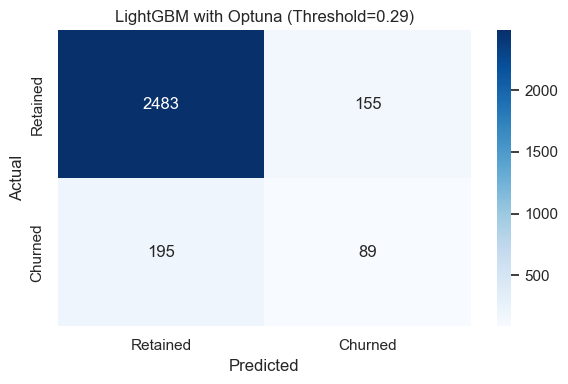

In [27]:
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'LightGBM with Optuna (Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

### 27. CLASSIFICATION REPORT

In [28]:
print("\n==== CLASSIFICATION REPORT ====")

print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=['Retained', 'Churned'],
        zero_division=0
    )
)


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.94      0.93      2638
     Churned       0.36      0.31      0.34       284

    accuracy                           0.88      2922
   macro avg       0.65      0.63      0.64      2922
weighted avg       0.87      0.88      0.88      2922



### 28. CROSS VALIDATION PERFORMANCE

In [29]:
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_lgbm_pipeline,
    X_model_train,
    y_model_train,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

### 29. CROSS VALIDATION TRAIN SCORES

In [30]:
print("\n==== CROSS VALIDATION TRAIN SCORES ====")

for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9891, Std: 0.0008
train_Precision - Mean: 0.9957, Std: 0.0018
train_Recall - Mean: 0.8921, Std: 0.0075
train_F1 - Mean: 0.9410, Std: 0.0043
train_ROC_AUC - Mean: 0.9998, Std: 0.0000
train_PR_AUC - Mean: 0.9980, Std: 0.0003


### 30. CROSS VALIDATION VALIDATION SCORES

In [31]:
print("\n==== CROSS VALIDATION VALIDATION SCORES ====")

for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.9072, Std: 0.0022
test_Precision - Mean: 0.6207, Std: 0.0728
test_Recall - Mean: 0.1233, Std: 0.0095
test_F1 - Mean: 0.2052, Std: 0.0131
test_ROC_AUC - Mean: 0.6873, Std: 0.0148
test_PR_AUC - Mean: 0.2863, Std: 0.0187


### 31. FEATURE IMPORTANCE

In [32]:
lgbm_model = best_lgbm_pipeline.named_steps['model']

feature_names = (
    best_lgbm_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = lgbm_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20))


==== TOP 20 IMPORTANT FEATURES ====
                       Feature  Importance
0           margin_net_pow_ele         784
1      forecast_meter_rent_12m         686
2       margin_per_consumption         550
3         cons_last_month_diff         517
4          forecast_cons_ratio         446
5                      pow_max         444
6   price_consumption_exposure         390
7             margin_per_power         381
8            months_modif_prod         377
9      price_power_interaction         365
10       cons_last_month_ratio         357
11        customer_value_proxy         347
12          margin_per_product         334
13           forecast_cons_12m         330
14       consumption_per_power         316
15                months_activ         312
16     var_year_price_off_peak         262
17             cons_last_month         250
18         forecast_year_ratio         238
19          off_peak_6m_change         231


### 32. FEATURE IMPORTANCE VISUALIZATION

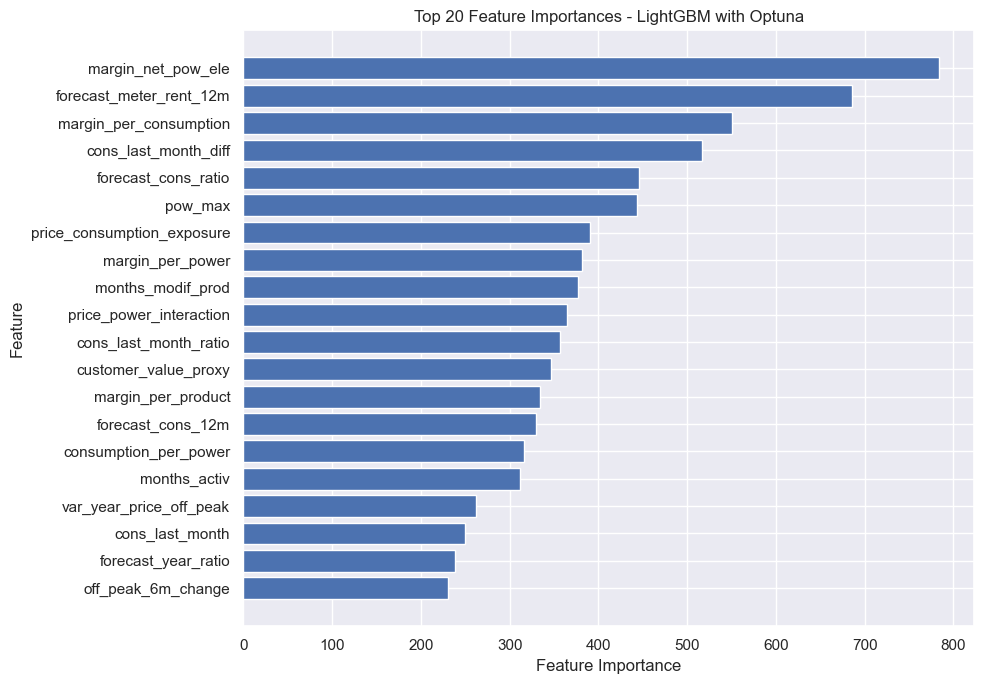

In [33]:
top_features = feature_importance_df.head(20).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - LightGBM with Optuna')
plt.tight_layout()
plt.show()

# **Observation: Exp 6 – LightGBM Classifier with Optuna Optimization**

**1. Model Optimization**

- Applied Optuna hyperparameter optimization to identify the best LightGBM configuration.
- Used 5-fold cross-validation with PR-AUC as the optimization metric.
- Class imbalance was considered using `scale_pos_weight`.
- Best hyperparameters:
  - `n_estimators`: 300
  - `max_depth`: 10
  - `learning_rate`: 0.0352
  - `num_leaves`: 49
  - `min_child_samples`: 25
  - `subsample`: 0.9276
  - `colsample_bytree`: 0.9807
  - `reg_alpha`: 3.0945
  - `reg_lambda`: 1.1303
  - `min_split_gain`: 0.0273
  - `scale_pos_weight`: 1.9661
- Best CV PR-AUC: **28.63%**

**Observation:**

- Optuna identified a configuration with good validation performance.
- CV PR-AUC improved compared to Exp5 Strongly Regularized XGBoost (26.38%).
- However, the training-validation performance gap remains significant.

**2. Model Performance – Test Data**

- Accuracy: **88.02%**
- Precision: **36.48%**
- Recall: **31.34%**
- F1 Score: **33.71%**
- ROC-AUC: **69.33%**
- PR-AUC: **32.20%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.29**, based on the highest F1 score in the threshold analysis.
- At threshold 0.29 (threshold validation):
  - Precision: 37.30%
  - Recall: 30.40%
  - F1 Score: 33.50%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**4. Confusion Matrix (Threshold = 0.29)**

- True Negatives: 2,483
- False Positives: 155
- False Negatives: 195
- True Positives: 89

**Observation:**

- Model correctly identifies 89 churn customers out of 284.
- It misses 195 actual churn customers.
- False positives are relatively low (155).

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 32.20% is slightly lower than Exp4 XGBoost (32.15% is marginally lower?).

**Correction:** Exp6 PR-AUC (32.20%) is slightly higher than Exp4 XGBoost (32.15%) and lower than Exp2 Regularized RF (35.75%).

**6. Cross-Validation Results**

- Training PR-AUC: 99.80%
- Validation accuracy: 90.72%
- Validation precision: 62.07%
- Validation recall: 12.33%
- Validation F1: 20.52%
- Validation ROC-AUC: 68.73%
- Validation PR-AUC: 28.63%

**Observation:**

- Large training-validation performance gap indicates overfitting.
- Validation recall is very low.
- Despite Optuna optimization, the model struggles to identify churn customers consistently during cross-validation.

**7. Top 20 Important Features**

The most important features include:

- margin_net_pow_ele
- forecast_meter_rent_12m
- margin_per_consumption
- cons_last_month_diff
- forecast_cons_ratio
- pow_max
- price_consumption_exposure
- margin_per_power
- months_modif_prod
- price_power_interaction

**Observation:**

- Margin-related, consumption-related and price-related features contribute significantly.
- These important features are largely consistent with previous Random Forest experiments.

**8. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strongly Reg. RF | Exp4-XGBoost | Exp5-Strongly Reg. XGB | Exp6-LightGBM |
| --------- | ---------------- | ------------------- | --------------------- | ------------ | ---------------------- | ------------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%                | **89.39%**   | 86.69%                 | 88.02%        |
| Precision | 26.72%           | 34.86%              | 29.26%                | **43.09%**   | 31.83%                 | 36.48%        |
| Recall    | 36.97%           | 34.86%              | **38.73%**            | 28.52%       | 32.39%                 | 31.34%        |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%                | 34.32%       | 32.11%                 | 33.71%        |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%                | 69.24%       | 69.58%                 | 69.33%        |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%                | 32.15%       | 29.42%                 | 32.20%        |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%                | 28.42%       | 26.38%                 | 28.63%        |

**Observation:**

- LightGBM achieves better precision than Exp2 and Exp3.
- Its test PR-AUC (32.20%) is better than Exp4 and Exp5.
- However, it does not outperform Exp2 in PR-AUC or F1 Score.
- Recall remains relatively low across the boosting models.

**Final Conclusion – LightGBM Classifier with Optuna**

- Optuna optimization improved model selection and achieved a test PR-AUC of 32.20%.
- Precision improved to 36.48%, but recall remains limited at 31.34%.
- Overfitting remains a concern despite hyperparameter optimization.
- LightGBM performs competitively but does not outperform the best Random Forest model.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Regularized Random Forest remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%). LightGBM provides competitive precision but does not improve overall churn identification.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.29 threshold. Compare classification metrics cautiously.